In [ ]:
!pip install -q torch transformers datasets matplotlib numpy pillow

In [2]:
import gc
import time
import warnings

import datasets
import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import transformers
from datasets import load_dataset
from transformers import (
    AutoConfig,
    AutoImageProcessor,
    AutoModel,
    AutoModelForCausalLM,
    AutoProcessor,
    AutoTokenizer,
)
from transformers.models.idefics3.modeling_idefics3 import Idefics3Connector
from transformers.models.qwen3_vl.modeling_qwen3_vl import Qwen3VLModel

warnings.filterwarnings("ignore")
transformers.logging.set_verbosity_error()
transformers.utils.logging.disable_progress_bar()
datasets.disable_progress_bars()

DEVICE = torch.device(
    "cuda"
    if torch.cuda.is_available()
    else "mps" if torch.backends.mps.is_available() else "cpu"
)
VISION_NAME = "google/siglip2-base-patch16-224"
MODEL_NAME = "Qwen/Qwen2.5-0.5B"
QWEN_VL_NAME = "Qwen/Qwen3-VL-2B-Instruct"
SMOLVLM_NAME = "HuggingFaceTB/SmolVLM-500M-Instruct"
PAIRS_NAME = "jxie/flickr8k"
NUM_TRAIN, NUM_VAL = 2000, 200
SEED = 0
torch.manual_seed(SEED)
print(f"DEVICE = {DEVICE}")

DEVICE = mps


# 1) Vision Language Models

- A vision-language model (VLM) lets a pretrained language model read images.
- The recipe that won is almost embarrassingly direct: run a pretrained vision encoder, map its patch features into the LLM's input embedding space with a small **bridge**, and splice the resulting vectors into the token sequence where the image belongs.
- The LLM never learns a new modality; it learns to read a new kind of "word".
- Everything specific to vision lives in three places: the bridge, how many visual tokens it produces, and how their 2D positions are encoded.

| Bridge | Visual tokens | Trained in | Used by |
|---|---|---|---|
| Linear / 2-layer MLP | one per patch | stage 1, then end-to-end | LLaVA-1.5, LLaVA-OneVision |
| Perceiver resampler (cross-attention to learned queries) | fixed $K$ (64) | stage 1 | Flamingo, IDEFICS, Qwen-VL v1 |
| Q-Former (queries + self- and cross-attention, 3 pretraining losses) | fixed 32 | separate pretraining | BLIP-2, InstructBLIP |
| Pixel shuffle / patch merger + MLP | patches ÷ $s^2$ | stage 1, then end-to-end | SmolVLM, InternVL, Qwen2/2.5/3-VL |
| Multi-level injection (DeepStack) | as above, plus features from several encoder layers added inside the LLM | end-to-end | Qwen3-VL |

- Three bridges are built from scratch and trained on the same frozen SigLIP 2 encoder and frozen Qwen2.5-0.5B, on real captioned photos;
- pixel shuffle and multimodal RoPE positions are checked against the implementations in SmolVLM and Qwen3-VL.

In [3]:
# Data: Flickr8k, 2,000 training and 200 held-out photos with five captions each
flickr = load_dataset(PAIRS_NAME)
train_rows = flickr["train"].shuffle(seed=SEED).select(range(NUM_TRAIN))
val_rows = flickr["validation"].select(range(NUM_VAL))
CAPTION_KEYS = [f"caption_{i}" for i in range(5)]
train_caps = [[r[k] for k in CAPTION_KEYS] for r in train_rows]
val_caps = [r["caption_0"] for r in val_rows]

# Create image processor and load frozen vision encoder
image_proc = AutoImageProcessor.from_pretrained(VISION_NAME)
encoder = (
    AutoModel.from_pretrained(VISION_NAME, dtype=torch.float32)
    .vision_model.to(DEVICE)
    .eval()
)


@torch.no_grad()
def encode_images(rows: datasets.Dataset, encoder: nn.Module) -> torch.Tensor:
    """Frozen SigLIP 2 patch features (N, 196, 768) in fp16 on CPU."""
    feats = []
    for s in range(0, len(rows), 64):
        images = [im.convert("RGB") for im in rows[s : s + 64]["image"]]
        pixels = image_proc(images=images, return_tensors="pt")["pixel_values"].to(
            DEVICE
        )
        feats.append(encoder(pixel_values=pixels).last_hidden_state.half().cpu())
    return torch.cat(feats)


# Encode all train and validation images into patch features
start = time.time()
train_feats = encode_images(train_rows, encoder)
val_feats = encode_images(val_rows, encoder)
print(
    f"patch features: train {tuple(train_feats.shape)}, val {tuple(val_feats.shape)} "
    f"| {time.time() - start:.0f} s"
)
del encoder
gc.collect()

patch features: train (2000, 196, 768), val (200, 196, 768) | 38 s


20

In [4]:
# Frozen SigLIP 2 ViT-B/16 and Qwen2.5-0.5B base; patch features are cached once
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)
llm = (
    AutoModelForCausalLM.from_pretrained(MODEL_NAME, dtype=torch.float32)
    .to(DEVICE)
    .eval()
)
llm.requires_grad_(False)
# Load tokenizer/LLM and extract reserved token ids and embed dim
VISION_START = tokenizer.convert_tokens_to_ids("<|vision_start|>")
VISION_END = tokenizer.convert_tokens_to_ids("<|vision_end|>")
IMAGE_PAD = tokenizer.convert_tokens_to_ids("<|image_pad|>")
EMBED_DIM = llm.config.hidden_size
print(
    f"{MODEL_NAME}: {sum(p.numel() for p in llm.parameters()) / 1e6:.0f} M params, "
    f"embed_dim {EMBED_DIM}"
)
print(
    f"reserved ids: vision_start {VISION_START}, vision_end {VISION_END}, image_pad "
    f"{IMAGE_PAD}"
)

Qwen/Qwen2.5-0.5B: 494 M params, embed_dim 896
reserved ids: vision_start 151652, vision_end 151653, image_pad 151655


# 2) Three Bridges from Scratch

In [5]:
def splice(
    visual: torch.Tensor, caption_ids: list[list[int]]
) -> dict[str, torch.Tensor]:
    """Build inputs_embeds, attention_mask and labels for a batch.

    visual (batch_num, K, EMBED_DIM) from a bridge; caption_ids are plain token ids.
    Layout: <vs> [K placeholders] <ve> caption <eos>, right-padded.
    """
    batch_num, k = visual.shape[:2]
    rows = [
        [VISION_START] + [IMAGE_PAD] * k + [VISION_END] + ids + [tokenizer.eos_token_id]
        for ids in caption_ids
    ]
    # one fixed length per bridge (captions are capped at 32 tokens) so MPS compiles one graph
    seq_len = k + 2 + 33
    input_ids = torch.full(
        (batch_num, seq_len), tokenizer.eos_token_id, dtype=torch.long
    )
    attention_mask = torch.zeros(batch_num, seq_len, dtype=torch.long)
    for i, r in enumerate(rows):
        input_ids[i, : len(r)] = torch.tensor(r)
        attention_mask[i, : len(r)] = 1
    input_ids, attention_mask = input_ids.to(DEVICE), attention_mask.to(DEVICE)
    embeds = llm.get_input_embeddings()(input_ids)
    # overwrite the placeholder rows with the bridge output
    embeds = embeds.masked_scatter(
        (input_ids == IMAGE_PAD)[..., None], visual.to(embeds.dtype)
    )
    labels = input_ids.clone()
    # supervise only the caption: image markers, placeholders and padding are ignored
    labels[:, : k + 2] = -100
    labels[attention_mask == 0] = -100
    return {"inputs_embeds": embeds, "attention_mask": attention_mask, "labels": labels}


def caption_loss(batch: dict[str, torch.Tensor]) -> torch.Tensor:
    """Next-token cross-entropy on caption tokens only.

    The LM head runs only where a label exists: full-vocabulary logits for every visual
    position (151,936 x seq_len floats per sequence) would dominate time and memory.
    """
    hidden = llm.model(
        inputs_embeds=batch["inputs_embeds"], attention_mask=batch["attention_mask"]
    ).last_hidden_state
    # position t predicts label t + 1
    targets = batch["labels"][:, 1:]
    keep = targets != -100
    logits = llm.lm_head(hidden[:, :-1][keep])
    return F.cross_entropy(logits.float(), targets[keep])


# Quick sanity-check of splice and caption_loss with toy inputs
toy = splice(torch.zeros(2, 4, EMBED_DIM, device=DEVICE), [[10, 11, 12], [20, 21]])
print(
    "inputs_embeds",
    tuple(toy["inputs_embeds"].shape),
    "| labels row 1:",
    toy["labels"][1].tolist(),
)
# same value as the library loss, which computes logits for every position
with torch.no_grad():
    batch = splice(
        torch.randn(2, 4, EMBED_DIM, device=DEVICE) * 0.02, [[10, 11, 12], [20, 21]]
    )
    print(
        f"caption_loss {caption_loss(batch):.5f} | llm(...).loss "
        f"{llm(**batch).loss:.5f}"
    )

inputs_embeds (2, 39, 896) | labels row 1: [-100, -100, -100, -100, -100, -100, 20, 21, 151643, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100]
caption_loss 8.53239 | llm(...).loss 8.53239


In [6]:
VISION_DIM = train_feats.shape[-1]
GRID = int(train_feats.shape[1] ** 0.5)


class MLPBridge(nn.Module):
    """LLaVA-1.5 projector: one LLM token per patch."""

    def __init__(self) -> None:
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(VISION_DIM, EMBED_DIM), nn.GELU(), nn.Linear(EMBED_DIM, EMBED_DIM)
        )

    def forward(self, v: torch.Tensor) -> torch.Tensor:
        """(batch_num, N, VISION_DIM) -> (batch_num, N, EMBED_DIM)."""
        return self.net(v)


def pixel_shuffle(v: torch.Tensor, s: int) -> torch.Tensor:
    """(batch_num, H*W, d) row-major grid -> (batch_num, H*W/s^2, s*s*d): fold s x s
    blocks into channels.
    """
    batch_num, n, d = v.shape
    h = int(n**0.5)
    # (B, H, W, d) -> (B, H/s, s, W/s, s, d) -> (B, H/s, W/s, s, s, d)
    blocks = v.view(batch_num, h // s, s, h // s, s, d).permute(0, 1, 3, 2, 4, 5)
    return blocks.reshape(batch_num, (h // s) ** 2, s * s * d)


class PixelShuffleBridge(nn.Module):
    """SmolVLM / InternVL style: fold s x s patches into one token, then an MLP."""

    def __init__(self, s: int = 2) -> None:
        super().__init__()
        self.s = s
        self.net = nn.Sequential(
            nn.Linear(s * s * VISION_DIM, EMBED_DIM),
            nn.GELU(),
            nn.Linear(EMBED_DIM, EMBED_DIM),
        )

    def forward(self, v: torch.Tensor) -> torch.Tensor:
        """(batch_num, N, VISION_DIM) -> (batch_num, N / s^2, EMBED_DIM)."""
        return self.net(pixel_shuffle(v, self.s))

The resampler uses `nn.MultiheadAttention` for the cross-attention; what is specific to it is
that the queries are parameters, so the output length is $K$ whatever $N$ is.

In [7]:
class PerceiverBridge(nn.Module):
    """Flamingo-style resampler: K learned queries cross-attend to the patches."""

    def __init__(
        self, num_queries: int = 32, num_layers: int = 2, num_heads: int = 14
    ) -> None:
        super().__init__()
        self.queries = nn.Parameter(torch.randn(num_queries, EMBED_DIM) * 0.02)
        self.kv_proj = nn.Linear(VISION_DIM, EMBED_DIM)
        self.attn = nn.ModuleList(
            [
                nn.MultiheadAttention(EMBED_DIM, num_heads, batch_first=True)
                for _ in range(num_layers)
            ]
        )
        self.mlp = nn.ModuleList(
            [
                nn.Sequential(
                    nn.LayerNorm(EMBED_DIM),
                    nn.Linear(EMBED_DIM, 2 * EMBED_DIM),
                    nn.GELU(),
                    nn.Linear(2 * EMBED_DIM, EMBED_DIM),
                )
                for _ in range(num_layers)
            ]
        )
        self.norm_q = nn.ModuleList(
            [nn.LayerNorm(EMBED_DIM) for _ in range(num_layers)]
        )
        self.out = nn.Linear(EMBED_DIM, EMBED_DIM)

    def forward(self, v: torch.Tensor) -> torch.Tensor:
        """(batch_num, N, VISION_DIM) -> (batch_num, K, EMBED_DIM)."""
        kv = self.kv_proj(v)
        q = self.queries.expand(len(v), -1, -1)
        for attn, mlp, norm in zip(self.attn, self.mlp, self.norm_q):
            q = q + attn(norm(q), kv, kv, need_weights=False)[0]
            q = q + mlp(q)
        return self.out(q)

In [8]:
# pixel shuffle vs SmolVLM's connector (a pure reshape, so no weights are needed)
smol_cfg = AutoConfig.from_pretrained(SMOLVLM_NAME)
with torch.device("meta"):
    smol_connector = Idefics3Connector(smol_cfg)
v = torch.randn(2, 64, 5)
theirs = smol_connector.pixel_shuffle(v, 2)
ours = pixel_shuffle(v, 2)
print(
    f"pixel_shuffle {tuple(v.shape)} -> {tuple(ours.shape)} | same multiset of values "
    "per token as SmolVLM: "
    f"{torch.allclose(ours.sort(-1).values, theirs.sort(-1).values)}"
)
# which patches land in token 0 and token 1 (patch index -> grid row, col)
probe = torch.arange(64.0).view(1, 64, 1)
for tok in (0, 1):
    idx = pixel_shuffle(probe, 2)[0, tok].long().tolist()
    print(f"token {tok} <- patches {[(i // 8, i % 8) for i in idx]}")

# Run each bridge on a small batch and print shapes and params
for bridge in (MLPBridge(), PixelShuffleBridge(2), PerceiverBridge(32)):
    out = bridge(train_feats[:2].float())
    print(
        f"{type(bridge).__name__:<20} {tuple(train_feats[:2].shape)} -> "
        f"{tuple(out.shape)} | "
        f"{sum(p.numel() for p in bridge.parameters()) / 1e6:.1f} M params"
    )

pixel_shuffle (2, 64, 5) -> (2, 16, 20) | same multiset of values per token as SmolVLM: True
token 0 <- patches [(0, 0), (0, 1), (1, 0), (1, 1)]
token 1 <- patches [(0, 2), (0, 3), (1, 2), (1, 3)]
MLPBridge            (2, 196, 768) -> (2, 196, 896) | 1.5 M params
PixelShuffleBridge   (2, 196, 768) -> (2, 49, 896) | 3.6 M params
PerceiverBridge      (2, 196, 768) -> (2, 32, 896) | 14.4 M params


SmolVLM orders the channels of a folded token differently (it interleaves the rows of a block
before concatenating), which is why the check compares the *set* of values each token
receives: both versions put exactly one $2 \times 2$ block into each token, and the linear
layer that follows is free to learn either channel order.

## 2.1 Multimodal RoPE position ids

In [9]:
def mrope_position_ids(
    input_ids: torch.Tensor, image_token: int, grid_hw: tuple[int, int]
) -> torch.Tensor:
    """(seq_len,) ids with one image of grid_hw merged tokens -> (3, seq_len) [t, h,
    w].
    """
    h, w = grid_hw
    pos = torch.zeros(3, len(input_ids), dtype=torch.long)
    is_img = (input_ids == image_token).nonzero()[:, 0]
    first, last = int(is_img[0]), int(is_img[-1])
    # text before the image: ordinary 1D positions on all three axes
    pos[:, :first] = torch.arange(first)
    p = first
    rows = torch.arange(h).repeat_interleave(w)
    cols = torch.arange(w).repeat(h)
    pos[0, first : last + 1] = p
    pos[1, first : last + 1] = p + rows
    pos[2, first : last + 1] = p + cols
    # text after the image restarts past the largest spatial extent
    after = len(input_ids) - last - 1
    pos[:, last + 1 :] = p + max(h, w) + torch.arange(after)
    return pos


# Build Qwen-VL processor and encode one example prompt
vl_cfg = AutoConfig.from_pretrained(QWEN_VL_NAME)
vl_proc = AutoProcessor.from_pretrained(QWEN_VL_NAME)
with torch.device("meta"):
    qwen_vl = Qwen3VLModel._from_config(vl_cfg)
image = val_rows[0]["image"].convert("RGB")
chat = [
    {
        "role": "user",
        "content": [{"type": "image"}, {"type": "text", "text": "Describe the photo."}],
    }
]
enc = vl_proc(
    text=[vl_proc.apply_chat_template(chat, add_generation_prompt=True)],
    images=[image],
    return_tensors="pt",
)
merge = vl_cfg.vision_config.spatial_merge_size
grid = (
    int(enc["image_grid_thw"][0, 1]) // merge,
    int(enc["image_grid_thw"][0, 2]) // merge,
)
# Compare our merged-position ids with Qwen3-VL reference
ref, _ = qwen_vl.get_rope_index(
    enc["input_ids"],
    enc["mm_token_type_ids"],
    image_grid_thw=enc["image_grid_thw"],
    attention_mask=enc["attention_mask"],
)
ours = mrope_position_ids(enc["input_ids"][0], vl_cfg.image_token_id, grid)
print(
    f"image {image.size} -> {grid[0]}x{grid[1]} merged visual tokens in a "
    f"{enc['input_ids'].shape[1]}-token prompt"
)
print(
    f"our (t, h, w) ids equal Qwen3-VL get_rope_index: {torch.equal(ours, ref[:, 0])}"
)
first = int((enc["input_ids"][0] == vl_cfg.image_token_id).nonzero()[0])
print("first image tokens (t, h, w):", ours[:, first : first + 4].T.tolist(), "...")
print("first text token after the image:", ours[:, first + grid[0] * grid[1]].tolist())
del qwen_vl

image (500, 333) -> 10x16 merged visual tokens in a 174-token prompt
our (t, h, w) ids equal Qwen3-VL get_rope_index: True
first image tokens (t, h, w): [[4, 4, 4], [4, 4, 5], [4, 4, 6], [4, 4, 7]] ...
first text token after the image: [20, 20, 20]


# 3) End-to-End: Stage-1 Alignment

- Each bridge is trained for the same number of steps with AdamW on random (photo, caption) pairs; only the bridge's parameters receive updates.
- The score is the caption cross-entropy on 200 held-out photos.
- Two controls bound it: the frozen LLM with **no image** (only the caption, which measures what the language model guesses unaided) and the trained MLP bridge fed the **wrong photo** (a shuffled batch), which shows how much of the gain is really coming from the image.

- Expect much of the initial reduction in caption loss to come from learning caption style rather than actual image grounding; the gap between right and wrong images measures the image's contribution.
- Typically style is learned quickly while real grounding requires far more pairs and steps, and different bridges often reach similar losses so reduced-token bridges can shorten sequences with little measurable cost.

In [10]:
STEPS, BATCH_NUM, LR = 120, 8, 1e-3


def caption_ids(captions: list[str]) -> list[list[int]]:
    """Tokenise captions without special tokens, capped at 32 tokens."""
    return [
        tokenizer(c.strip(), add_special_tokens=False)["input_ids"][:32]
        for c in captions
    ]


@torch.no_grad()
def val_loss(bridge: nn.Module | None, shuffle: bool = False) -> float:
    """Mean caption cross-entropy on the held-out photos (bridge None = no image)."""
    losses = []
    for s in range(0, NUM_VAL, 20):
        ids = caption_ids(val_caps[s : s + 20])
        if bridge is None:
            # same layout with zero visual tokens: <vs> <ve> caption <eos>
            empty = torch.zeros(len(ids), 0, EMBED_DIM, device=DEVICE)
            losses.append(caption_loss(splice(empty, ids)).item())
            continue
        feats = val_feats[s : s + 20]
        if shuffle:
            feats = feats.roll(1, dims=0)
        losses.append(
            caption_loss(splice(bridge(feats.float().to(DEVICE)), ids)).item()
        )
    return float(np.mean(losses))


def train_bridge(bridge: nn.Module) -> tuple[nn.Module, list[float]]:
    """Stage-1 training of one bridge with the LLM frozen."""
    torch.manual_seed(SEED)
    start = time.time()
    bridge = bridge.to(DEVICE)
    opt = torch.optim.AdamW(bridge.parameters(), lr=LR, weight_decay=0.01)
    sched = torch.optim.lr_scheduler.OneCycleLR(
        opt, LR, total_steps=STEPS, pct_start=0.1
    )
    history = []
    for step in range(STEPS):
        idx = torch.randint(0, NUM_TRAIN, (BATCH_NUM,))
        caps = [train_caps[i][np.random.randint(5)] for i in idx.tolist()]
        loss = caption_loss(
            splice(bridge(train_feats[idx].float().to(DEVICE)), caption_ids(caps))
        )
        opt.zero_grad()
        loss.backward()
        opt.step()
        sched.step()
        history.append(loss.item())
        if (step + 1) % 30 == 0:
            print(
                f"  step {step + 1:>3}  loss {np.mean(history[-30:]):.3f}  "
                f"({time.time() - start:.0f} s)"
            )
    return bridge.eval(), history


# Report validation loss for LLM without image input
print(f"no image (LLM alone): val caption loss {val_loss(None):.3f}")

no image (LLM alone): val caption loss 4.996


In [11]:
results, curves = {}, {}


def run_bridge(name: str, bridge: nn.Module) -> None:
    """Train one bridge and print its held-out caption loss."""
    start = time.time()
    trained, history = train_bridge(bridge)
    results[name] = (trained, val_loss(trained))
    curves[name] = history
    params = sum(p.numel() for p in trained.parameters()) / 1e6
    print(
        f"{name:<30} val loss {results[name][1]:.3f} | {params:.1f} M params | "
        f"{time.time() - start:.0f} s"
    )


# Train and evaluate the MLP bridge, storing results
run_bridge("MLP (196 tokens)", MLPBridge())

  step  30  loss 3.330  (49 s)


  step  60  loss 2.624  (97 s)


  step  90  loss 2.613  (146 s)


  step 120  loss 2.566  (195 s)


MLP (196 tokens)               val loss 2.479 | 1.5 M params | 213 s


In [12]:
# Train and evaluate the pixel-shuffle bridge
run_bridge("pixel shuffle s=2 (49 tokens)", PixelShuffleBridge(2))

  step  30  loss 3.237  (19 s)


  step  60  loss 2.695  (38 s)


  step  90  loss 2.603  (57 s)


  step 120  loss 2.583  (77 s)


pixel shuffle s=2 (49 tokens)  val loss 2.491 | 3.6 M params | 87 s


  step  30  loss 3.225  (18 s)


  step  60  loss 2.755  (36 s)


  step  90  loss 2.529  (53 s)


  step 120  loss 2.537  (70 s)


Perceiver (32 tokens)          val loss 2.485 | 14.4 M params | 79 s


MLP, wrong photo               val loss 2.589


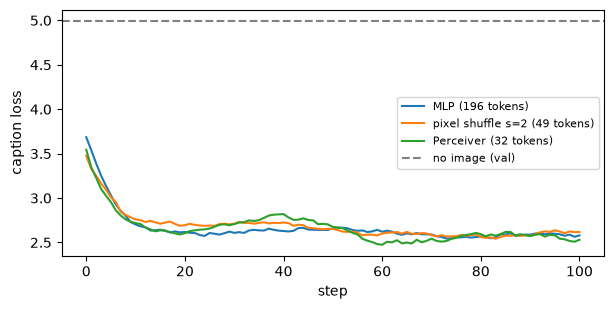

In [13]:
# Train and evaluate the Perceiver bridge and compute shuffling loss
run_bridge("Perceiver (32 tokens)", PerceiverBridge(32))
print(
    f"{'MLP, wrong photo':<30} val loss "
    f"{val_loss(results['MLP (196 tokens)'][0], shuffle=True):.3f}"
)

# Plot training curves for each bridge and show no-image baseline
plt.figure(figsize=(7, 3.2))
for name, h in curves.items():
    plt.plot(np.convolve(h, np.ones(20) / 20, mode="valid"), label=name)
plt.axhline(val_loss(None), color="grey", ls="--", label="no image (val)")
plt.xlabel("step")
plt.ylabel("caption loss")
plt.legend(fontsize=8)
plt.show()

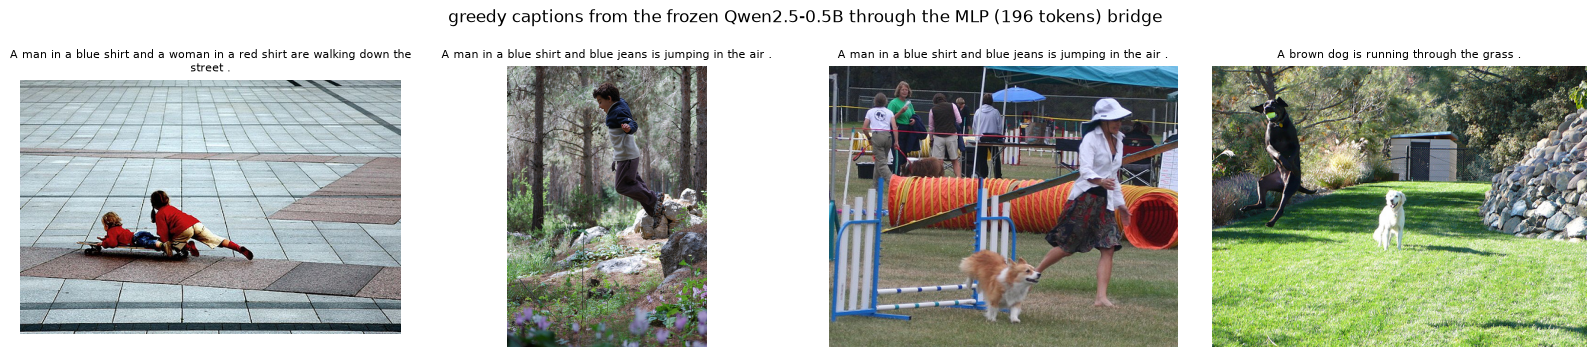

model: A man in a blue shirt and a woman in a red shirt are walking down the street .
human: the boy laying face down on a skateboard is being pushed along the ground by another boy .



model: A man in a blue shirt and blue jeans is jumping in the air .
human: a boy in a blue top is jumping off some rocks in the woods .



model: A man in a blue shirt and blue jeans is jumping in the air .
human: A lady walking her dog through an obstacle course , while other people are in the background .



model: A brown dog is running through the grass .
human: a big black dog jumps in the air to catch the tennis ball in his mouth .



In [14]:
@torch.no_grad()
def caption(bridge: nn.Module, feats: torch.Tensor, max_new_tokens: int = 24) -> str:
    """Greedy caption from the frozen LLM given one image's patch features (N,
    VISION_DIM).
    """
    visual = bridge(feats[None].float().to(DEVICE))
    prefix = splice(visual, [[]])
    # keep <vs> visual tokens <ve> only: drop the caption padding splice adds for training
    embeds = prefix["inputs_embeds"][:, : visual.shape[1] + 2]
    out = llm.generate(
        inputs_embeds=embeds,
        attention_mask=torch.ones(embeds.shape[:2], dtype=torch.long, device=DEVICE),
        max_new_tokens=max_new_tokens,
        do_sample=False,
        pad_token_id=tokenizer.eos_token_id,
    )
    return tokenizer.decode(out[0], skip_special_tokens=True).strip()


# Generate greedy captions for best bridge and display examples
best = min(results, key=lambda n: results[n][1])
fig, axes = plt.subplots(1, 4, figsize=(16, 3.6))
for ax, i in zip(axes, range(4)):
    ax.imshow(val_rows[i]["image"])
    ax.axis("off")
    ax.set_title(caption(results[best][0], val_feats[i]), fontsize=8, wrap=True)
plt.suptitle(f"greedy captions from the frozen Qwen2.5-0.5B through the {best} bridge")
plt.tight_layout()
plt.show()
for i in range(4):
    print(f"model: {caption(results[best][0], val_feats[i])}\nhuman: {val_caps[i]}\n")

# Summary

- **Token budget is the real design variable.** Visual tokens dominate the sequence (196 here
  against ~15 caption tokens; 1–3k for a document page at native resolution), and LLM cost is
  linear in them for the MLP and quadratic in attention. Pixel shuffle and Qwen's 2 × 2 merger
  cut tokens by 4× with little loss; resamplers cut further but lose fine detail, which is why
  they fell out of favour for OCR-heavy models.
- **Stage 2 matters more than the bridge.** After alignment, unfreezing the LLM on instruction
  data (LLaVA-style), and for frontier models the encoder too, is where most capability comes
  from. MLP vs. Q-Former differences mostly vanish once the LLM is trained end-to-end.
- **Resolution.** Fixed 224 px loses text and small objects. Production VLMs tile the image
  (LLaVA-NeXT, SmolVLM, InternVL) or run the encoder at native resolution with 2D RoPE inside
  the ViT (Qwen2-VL onward, SigLIP 2 NaFlex), and use mRoPE in the LLM so positions reflect the
  real grid.
- **Data.** Stage-1 alignment uses hundreds of thousands to millions of captioned images
  (LLaVA used 558k); this run's 2,000 photos and 120 steps only show the direction.

| Piece | Built | Checked against |
|---|---|---|
| Splicing visual tokens into the sequence | placeholder rows overwritten, caption-only labels | trained end-to-end |
| MLP bridge | 2-layer GELU MLP, $K = N$ | caption loss vs no-image and wrong-image controls |
| Pixel-shuffle bridge | $s \times s$ fold + MLP, $K = N/s^2$ | SmolVLM `Idefics3Connector.pixel_shuffle` |
| Perceiver resampler | learned queries + cross-attention, fixed $K$ | same training budget |
| Multimodal RoPE ids | $(t, h, w)$ per token, text restarts after $\max(H, W)$ | Qwen3-VL `get_rope_index` |